In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pysmithchart
from pysmithchart.constants import Z_DOMAIN, NORM_Z_DOMAIN, R_DOMAIN
from pysmithchart import utils

In [3]:
Z0 = 50
ZL = 80+1j*65
zL = ZL/Z0
f = 500e6
print(f"Impedancia normalizada: zL = {zL}")
yL = 1/zL
print(f"Admitancia normalizada: yL = {yL}")
gL = yL.real
vswr = utils.calc_vswr(Z0, ZL)
print(f"VSWR: {vswr}")
text_box = dict(facecolor='lightyellow')
y_found = 0.3765-0.4845j
b = y_found-yL
print("---------- Acoplamiento con red L ----------\n")
print(f"Susceptancia encontrada: b = {b}") 
L = Z0/(2*3.1416*f*abs(b.imag))
print(f"Valor del inductor: L = {L} H")
r_found = 1-1.38j
x = -r_found.imag
C = 1/(2*3.1416*f*Z0*abs(x))
print(f"Valor del capacitor: C = {C} F")

Impedancia normalizada: zL = (1.6+1.3j)
Admitancia normalizada: yL = (0.3764705882352941-0.3058823529411765j)
VSWR: 2.941259610728548
---------- Acoplamiento con red L ----------

Susceptancia encontrada: b = (2.941176470588891e-05-0.1786176470588235j)
Valor del inductor: L = 8.910349763305471e-08 H
Valor del capacitor: C = 4.613175968674691e-12 F


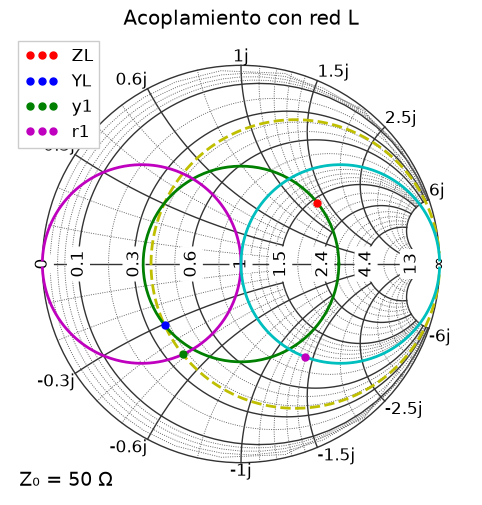

In [4]:
# Parte 1: acoplamiento red L
plt.figure(figsize=(6, 6))
ax = plt.subplot(111, projection='smith')

ax.plot_constant_resistance(gL, "y--") #círculo g+jB
ax.plot_vswr(vswr,"g")
ax.plot_constant_conductance(1.0, "m") #círculo 1+jX rotado o admitancia constante
ax.plot_constant_resistance(1.0, "c") #círculo 1+jX
ax.plot(zL, 'ro', label='ZL', domain=NORM_Z_DOMAIN)
ax.plot(yL, 'bo', label='YL', domain=NORM_Z_DOMAIN)
ax.plot(y_found, 'go',label='y1', domain=NORM_Z_DOMAIN)
ax.plot(r_found, 'mo', label='r1', domain=NORM_Z_DOMAIN)
plt.legend()
plt.title("Acoplamiento con red L")
plt.show()

---------- Acoplamiento con 1 stub shunt ----------

---------- Acoplamiento stubs en serie ----------

Longitud de onda stub 1: 0.3349850086903152 lambda, 
 longitud de onda stub 2: 0.16501499130968478 lambda
Longitud de onda carga: 0.19630582186931933 lambda
Distancia stub 1: 0.1386791868209959 lambda, 
 distancia stub 2: 0.46870916944036545 lambda
---------- Acoplamiento stubs shunt ----------

Longitud de onda admitancia: 0.44630582186931933 lambda
Distancia stub 1: 0.3886791868209959 lambda, 
 distancia stub 2: 0.21870916944036545 lambda


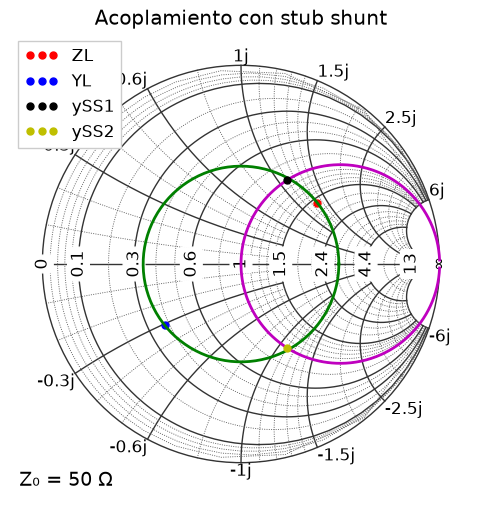

In [5]:
# Parte 2: acoplamiento con un stub shunt
print("---------- Acoplamiento con 1 stub shunt ----------\n")
ySS1 = 1+1.1j
ySS2 = 1-1.1j
def get_wavelength_positions(entry, is_impedance=True):
    """Calculates Wavelengths Toward Load (WTL) and Toward Generator (WTG).

    Parameters:
        entry (complex): Normalized impedance 'z' or reflection coefficient
        'gamma'.
        is_impedance (bool): True if entry is 'z', False if entry is 'gamma'.

    Returns:
        tuple: (wtl, wtg) in units of lambda (0.0 to 0.5)
    """
    if is_impedance:
        gamma = (entry - 1) / (entry + 1)
    else:
        gamma = entry

    # Phase angle in radians [-pi, pi]
    phi = np.angle(gamma)

    # WTL (Counter-clockwise from Short Circuit at phi = pi)
    wtl = (0.25 + phi / (4 * np.pi)) % 0.5

    # WTG (Clockwise from Short Circuit at phi = pi)
    wtg = (0.25 - phi / (4 * np.pi)) % 0.5

    return wtl, wtg
# funcion para obtener las distancias de los stubs, sumando 0.5 si son negativas
d_stub = lambda wtl, wtgl: (wtl - wtgl + 0.5) % 0.5
print("---------- Acoplamiento stubs en serie ----------\n")
wtl1, _ = get_wavelength_positions(ySS1, is_impedance=True)
wtl2, _ = get_wavelength_positions(ySS2, is_impedance=True)
wtll, wtgl = get_wavelength_positions(zL, is_impedance=True)
d1s = d_stub(wtl1, wtgl)
d2s = d_stub(wtl2, wtgl)
# las longitudes de onda de los stubs se obtienen con respecto a la carga
print(f"Longitud de onda stub 1: {wtl1} lambda, \n longitud de onda stub 2: {wtl2} lambda")
# la longitud de onda de la carga se obtiene con respecto al generador
print(f"Longitud de onda carga: {wtgl} lambda")
print(f"Distancia stub 1: {d1s} lambda, \n distancia stub 2: {d2s} lambda")
print("---------- Acoplamiento stubs shunt ----------\n")
wtly, wtgy = get_wavelength_positions(yL, is_impedance=True)
print(f"Longitud de onda admitancia: {wtgy} lambda")
d1p = d_stub(wtl1, wtgy)
d2p = d_stub(wtl2, wtgy)
print(f"Distancia stub 1: {d1p} lambda, \n distancia stub 2: {d2p} lambda")
plt.figure(figsize=(6, 6))
ax = plt.subplot(111, projection='smith')
ax.plot(zL, 'ro', label='ZL', domain=NORM_Z_DOMAIN)
ax.plot(yL, 'bo', label='YL', domain=NORM_Z_DOMAIN)
ax.plot_vswr(vswr,"g")
ax.plot_constant_resistance(1.0, "m") #círculo 1+jX
ax.plot(ySS1, 'ko',label='ySS1', domain=NORM_Z_DOMAIN)
ax.plot(ySS2, 'yo', label='ySS2', domain=NORM_Z_DOMAIN)
plt.legend()
plt.title("Acoplamiento con stub shunt")
plt.show()

### Acoplamiento con dos stubs

---------- Acoplamiento con dos stubs ----------

Puntos intersección entre la rotación 0.375 del círculo r=1+jX y el círculo de VSWR

y1a = (0.3765-0.23j), y1b = (0.547-1.885j)
Valor considerado: (0.3765-0.23j)
Valor de b1: 0.0759
Longitud de onda stub 1: 0.0121 lambda
------------Segundo stub------------

Valor de b2: 1.0200
Longitud de onda stub 2: 0.1266 lambda


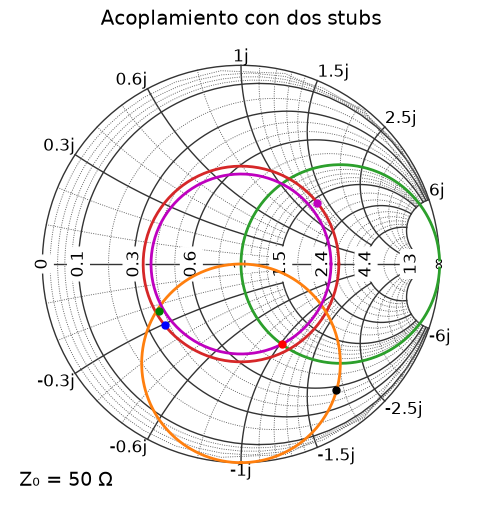

In [8]:
def make_rotated_circle(lambda_fraction):
    # ---- 1. Build the r = 1 circle directly in the Γ plane ----
    r      = 1.0
    center = r / (1.0 + r)          # 0.5
    radius = 1.0 / (1.0 + r)        # 0.5
    theta  = np.linspace(0.0, 2.0 * np.pi, 1441)
    gamma  = center + radius * np.exp(1j * theta)
    if lambda_fraction == 0.125:
        # ---- 3. Rotate λ/8 toward the load  →  multiply by j ----
        gamma = gamma * 1j
    elif lambda_fraction == 0.375:
        # ---- 3. Rotate 3λ/8 toward the load  →  multiply by -j ----
        gamma = gamma * -1j
    else:
        raise ValueError("Invalid lambda_fraction. Use 0.125 or 0.375.")
    return gamma
# valores de los puntos de intersección de interés
print("---------- Acoplamiento con dos stubs ----------\n")
y1a = 0.3765-0.23j
y1b = 0.547-1.885j

rho= abs((y1a.real-1)/(y1a.real+1))
vswr2 = (1+rho)/(1-rho)
fig = plt.figure(figsize=(6, 6))
ax = fig.add_subplot(111, projection="smith", domain=R_DOMAIN)
lambda_fraction = 3/8
gamma_rot = make_rotated_circle(lambda_fraction)
print(f"Puntos intersección entre la rotación {lambda_fraction} del círculo r=1+jX y el círculo de VSWR\n")
print(f"y1a = {y1a}, y1b = {y1b}")
print(f"Valor considerado: {y1a}")
jb = y1a.imag-yL.imag
b1 = float(jb.real)
stub1_length = np.atan(b1)/(2*np.pi)
print(f"Valor de b1: {jb.real:.4f}")
print(f"Longitud de onda stub 1: {stub1_length:.4f} lambda")
print("------------Segundo stub------------\n")
y2 = 1-1.02j
b2 = abs(float(y2.imag))
stub2_length = np.atan(b2)/(2*np.pi)
print(f"Valor de b2: {b2:.4f}")
print(f"Longitud de onda stub 2: {stub2_length:.4f} lambda")

# ---- 4. Rotated circle: no markers ----
ax.plot_constant_resistance(1.0, color="C2", marker="") #círculo 1+jX
ax.plot_vswr(vswr, color="C3", marker="") #círculo 1+jX
ax.plot(gamma_rot.real, gamma_rot.imag,
        color="C1", lw=2,
        marker="",
        linestyle="-", label="r = 1+jX rotación 3λ/8")
ax.plot_vswr(vswr2, color="m", marker="") #círculo 1+jX
ax.plot(zL, 'mo', label='ZL', domain=NORM_Z_DOMAIN)
ax.plot(yL, 'bo', label='YL', domain=NORM_Z_DOMAIN)
ax.plot(y1a, 'go', label='y1a', domain=NORM_Z_DOMAIN)
ax.plot(y1b, 'ko', label='y1b', domain=NORM_Z_DOMAIN)
ax.plot(y2, 'ro', label='y2', domain=NORM_Z_DOMAIN)
ax.title.set_text("Acoplamiento con dos stubs")

plt.show()